In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
crime = pd.read_csv("Crime_Data_from_2020_to_Present.csv")

## Data Exploration

In [2]:
# overview
crime.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,3/1/2020 0:00,3/1/2020 0:00,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,2/9/2020 0:00,2/8/2020 0:00,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11/11/2020 0:00,11/4/2020 0:00,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,5/10/2023 0:00,3/10/2020 0:00,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,200412582,9/9/2020 0:00,9/9/2020 0:00,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,200 E AVENUE 28,NaN,34.0820,-118.2130


In [3]:
# rows and columns
crime.shape

(1005198, 28)

In [4]:
# list of columns
crime.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON'],
      dtype='str')

In [5]:
# non-null counts and data types per column
crime.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005198 entries, 0 to 1005197
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1005198 non-null  int64  
 1   Date Rptd       1005198 non-null  str    
 2   DATE OCC        1005198 non-null  str    
 3   TIME OCC        1005198 non-null  int64  
 4   AREA            1005198 non-null  int64  
 5   AREA NAME       1005198 non-null  str    
 6   Rpt Dist No     1005198 non-null  int64  
 7   Part 1-2        1005198 non-null  int64  
 8   Crm Cd          1005198 non-null  int64  
 9   Crm Cd Desc     1005198 non-null  str    
 10  Mocodes         853438 non-null   str    
 11  Vict Age        1005198 non-null  int64  
 12  Vict Sex        860416 non-null   str    
 13  Vict Descent    860404 non-null   str    
 14  Premis Cd       1005182 non-null  float64
 15  Premis Desc     1004610 non-null  str    
 16  Weapon Used Cd  327280 non-null   float64
 17  

In [6]:
# null counts per column
crime.isnull().sum()[crime.isnull().sum() > 0]

Mocodes            151760
Vict Sex           144782
Vict Descent       144794
Premis Cd              16
Premis Desc           588
Weapon Used Cd     677918
Weapon Desc        677918
Status                  1
Crm Cd 1               11
Crm Cd 2           936039
Crm Cd 3          1002884
Crm Cd 4          1005134
Cross Street       850955
dtype: int64

In [7]:
# checking DR_NO column is unique
crime["DR_NO"].nunique()

1005198

In [8]:
# duplicate counts per column
crime.duplicated().sum()

np.int64(0)

In [9]:
# summary statistics
pd.options.display.float_format = "{:,.2f}".format
crime.describe()

,DR_NO,TIME OCC,AREA,Rpt Dist No,Part 1-2,Crm Cd,Vict Age,Premis Cd,Weapon Used Cd,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LAT,LON
count,"1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,182.00","327,280.00","1,005,187.00","69,159.00","2,314.00",64.00,"1,005,198.00","1,005,198.00"
mean,"220,227,677.87","1,339.91",10.69,"1,115.56",1.40,500.15,28.91,305.62,363.95,499.91,958.11,984.02,991.22,34.00,-118.09
std,"13,202,822.08",651.05,6.11,611.17,0.49,205.26,21.99,219.32,123.74,205.06,110.35,52.35,27.07,1.61,5.58
min,817.00,1.00,1.00,101.00,1.00,110.00,-4.00,101.00,101.00,110.00,210.00,310.00,821.00,0.00,-118.67
25%,"210,616,927.25",900.00,5.00,587.00,1.00,331.00,0.00,101.00,311.00,331.00,998.00,998.00,998.00,34.01,-118.43
50%,"220,916,044.00","1,420.00",11.00,"1,139.00",1.00,442.00,30.00,203.00,400.00,442.00,998.00,998.00,998.00,34.06,-118.32
75%,"231,110,516.25","1,900.00",16.00,"1,613.00",2.00,626.00,44.00,501.00,400.00,626.00,998.00,998.00,998.00,34.16,-118.27
max,"252,104,146.00","2,359.00",21.00,"2,199.00",2.00,956.00,120.00,976.00,516.00,956.00,999.00,999.00,999.00,34.33,0.00


In [10]:
# invalid ages
crime[crime["Vict Age"] <= 0]["Vict Age"].value_counts()

Vict Age
 0    269377
-1        99
-2        28
-3         6
-4         3
Name: count, dtype: int64

In [11]:
# age outliers
crime[crime["Vict Age"] >= 100]["Vict Age"].value_counts()

Vict Age
120    1
Name: count, dtype: int64

In [12]:
# missing LAT values
crime[crime["LAT"] == 0]["LAT"].value_counts()

LAT
0.00    2240
Name: count, dtype: int64

In [13]:
# missing LON values
crime[crime["LON"] == 0]["LON"].value_counts()

LON
0.00    2240
Name: count, dtype: int64

In [14]:
# checking missing values belong to same rows
crime[(crime["LAT"] == 0) & (crime["LON"] == 0)].shape[0]

2240

In [15]:
# missing value placeholders
placeholders = [
    "NA",
    "na",
    "Na",
    "N/A",
    "n/a",
    "N.A.",
    "none",
    "None",
    "NONE",
    "missing",
    "Missing",
    "unknown",
    "Unknown",
    "UNK",
    "undefined",
    "-",
    "?",
    "x",
    "X",
    "",
    " ",
    "   ",
]
missing_counts = crime.isin(placeholders).sum()[crime.isin(placeholders).sum() > 0]
missing_counts

Vict Sex         97787
Vict Descent    106701
Status Desc          7
LOCATION             1
dtype: int64

In [16]:
# Vict Sex missing values
crime["Vict Sex"].value_counts()

Vict Sex
M    403916
F    358599
X     97786
H       114
-         1
Name: count, dtype: int64

In [17]:
# Vict Descent missing values
crime["Vict Descent"].value_counts()

Vict Descent
H    296437
W    201451
B    135823
X    106699
O     78010
A     21340
K      5991
F      4838
C      4631
J      1586
V      1195
I      1015
Z       577
P       288
U       221
D        91
L        77
G        74
S        58
-         2
Name: count, dtype: int64

In [18]:
# Status Desc missing values
crime["Status Desc"].value_counts()

Status Desc
Invest Cont     803946
Adult Other     109255
Adult Arrest     86877
Juv Arrest        3249
Juv Other         1864
UNK                  7
Name: count, dtype: int64

In [19]:
# LOCATION missing values
pd.set_option("display.max_rows", None)
crime["LOCATION"].value_counts()

LOCATION
800 N  ALAMEDA                      ST      2598
700 S  FIGUEROA                     ST      1711
100    THE GROVE                    DR      1688
10200    SANTA MONICA                 BL    1657
6TH                          ST             1585
11800    SANTA MONICA                 BL    1526
7TH                          ST             1502
9300    TAMPA                        AV     1452
7TH                                         1447
6TH                                         1372
600 S  ALVARADO                     ST      1363
5300    LANKERSHIM                   BL     1255
6600    TOPANGA CANYON               BL     1222
FIGUEROA                     ST             1217
HOLLYWOOD                                   1212
VERMONT                      AV             1194
BROADWAY                                    1188
5TH                                         1149
WESTERN                      AV             1090
8TH                          ST             1071
400 S  LA B

## Data Cleaning

In [20]:
# dropping irrelevant columns
columns_to_drop = [
    "AREA",
    "Rpt Dist No",
    "Part 1-2",
    "Crm Cd",
    "Mocodes",
    "Premis Cd",
    "Premis Desc",
    "Weapon Used Cd",
    "Weapon Desc",
    "Status",
    "Crm Cd 1",
    "Crm Cd 2",
    "Crm Cd 3",
    "Crm Cd 4",
    "LOCATION",
    "Cross Street"
]
crime = crime.drop(columns=columns_to_drop)

In [21]:
crime.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA NAME',
       'Crm Cd Desc', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Status Desc',
       'LAT', 'LON'],
      dtype='str')

In [22]:
# replacing missing value placeholders with NaN
crime.replace("-", np.nan, inplace=True)

In [23]:
crime["Vict Descent"] = crime["Vict Descent"].replace("X", np.nan)

In [24]:
crime["Vict Descent"].value_counts(dropna=False)

Vict Descent
H      296437
NaN    251495
W      201451
B      135823
O       78010
A       21340
K        5991
F        4838
C        4631
J        1586
V        1195
I        1015
Z         577
P         288
U         221
D          91
L          77
G          74
S          58
Name: count, dtype: int64

In [25]:
crime["Vict Sex"] = crime["Vict Sex"].replace("H", np.nan)

In [26]:
crime["Vict Sex"] = crime["Vict Sex"].replace("X", np.nan)

In [27]:
crime["Vict Sex"].value_counts(dropna=False)

Vict Sex
M      403916
F      358599
NaN    242683
Name: count, dtype: int64

In [28]:
crime.replace("UNK", np.nan, inplace=True)

In [29]:
crime["Status Desc"].value_counts(dropna=False)

Status Desc
Invest Cont     803946
Adult Other     109255
Adult Arrest     86877
Juv Arrest        3249
Juv Other         1864
NaN                  7
Name: count, dtype: int64

In [30]:
# replacing invalid ages with NaN
crime.loc[crime["Vict Age"] < 0, "Vict Age"] = np.nan

In [31]:
crime[crime["Vict Age"] < 0]["Vict Age"].value_counts()

Series([], Name: count, dtype: int64)

In [32]:
# replacing missing values with NaN
crime["LAT"] = crime["LAT"].replace(0, np.nan)

In [33]:
crime["LON"] = crime["LON"].replace(0, np.nan)

In [34]:
crime[(crime["LAT"] == 0) & (crime["LON"] == 0)].shape[0]

0

In [35]:
# converting to datetime
crime["Date Rptd"] = pd.to_datetime(crime["Date Rptd"])
crime["DATE OCC"] = pd.to_datetime(crime["DATE OCC"])
crime["TIME OCC"] = crime["TIME OCC"].astype(str).str.zfill(4)
crime["TIME OCC"] = pd.to_datetime(crime["TIME OCC"], format="%H%M").dt.hour

In [36]:
crime.dtypes

DR_NO                    int64
Date Rptd       datetime64[us]
DATE OCC        datetime64[us]
TIME OCC                 int32
AREA NAME                  str
Crm Cd Desc                str
Vict Age               float64
Vict Sex                   str
Vict Descent               str
Status Desc                str
LAT                    float64
LON                    float64
dtype: object

In [37]:
# extracting day of week
crime["day_of_week"] = crime["DATE OCC"].dt.day_name()

In [38]:
crime["day_of_week"].value_counts(dropna=False)

day_of_week
Friday       153715
Saturday     147474
Wednesday    142756
Thursday     141861
Monday       141568
Sunday       139662
Tuesday      138162
Name: count, dtype: int64

In [39]:
# extracting month
crime["month"] = crime["DATE OCC"].dt.month_name()

In [40]:
crime["month"].value_counts(dropna=False)

month
January      92776
March        87859
February     86490
October      84128
July         83962
August       83851
April        83517
May          83014
June         81384
September    81016
November     78977
December     78224
Name: count, dtype: int64

In [41]:
# extracting year
crime["year"] = crime["DATE OCC"].dt.year
crime["year"].value_counts().sort_index()

year
2020    199847
2021    209875
2022    235258
2023    232350
2024    127574
2025       294
Name: count, dtype: int64

In [42]:
# dropping 2024-2025 data
crime = crime[crime["year"].between(2020, 2023)]

In [43]:
crime["year"].value_counts().sort_index()

year
2020    199847
2021    209875
2022    235258
2023    232350
Name: count, dtype: int64

In [44]:
# populating Vict Descent descriptions
ethnicity_mapping = {
    "A": "Other Asian",
    "B": "Black",
    "C": "Chinese",
    "D": "Cambodian",
    "F": "Filipino",
    "G": "Guamanian",
    "H": "Hispanic/Latin/Mexican",
    "I": "American Indian/Alaskan Native",
    "J": "Japanese",
    "K": "Korean",
    "L": "Laotian",
    "O": "Other",
    "P": "Pacific Islander",
    "S": "Samoan",
    "U": "Hawaiian",
    "V": "Vietnamese",
    "W": "White",
    "Z": "Asian Indian",
}
crime["Vict Descent"] = crime["Vict Descent"].replace(ethnicity_mapping)

In [45]:
crime["Vict Descent"].value_counts(dropna=False)

Vict Descent
Hispanic/Latin/Mexican            267795
NaN                               202117
White                             178474
Black                             124097
Other                              69458
Other Asian                        19247
Korean                              4796
Filipino                            3754
Chinese                             3477
Japanese                            1236
Vietnamese                           929
American Indian/Alaskan Native       839
Asian Indian                         452
Pacific Islander                     238
Hawaiian                             175
Cambodian                             74
Guamanian                             64
Laotian                               59
Samoan                                49
Name: count, dtype: int64

In [46]:
# age group categories
bins = [0, 17, 29, 39, 49, 59, 69, 79, 89, 150]
labels = ["Under 18", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"]
crime["age_group"] = pd.cut(crime["Vict Age"], bins=bins, labels=labels)
crime["age_group"] = crime["age_group"].cat.add_categories(["Non-Individual"])
crime.loc[crime["Vict Age"] == 0, "age_group"] = "Non-Individual"

In [47]:
crime["age_group"].value_counts(dropna=False)

age_group
Non-Individual    218450
18-29             173903
30-39             173884
40-49             116558
50-59              89002
60-69              53532
Under 18           23471
70-79              20924
80-89               5996
90+                 1474
NaN                  136
Name: count, dtype: int64

In [48]:
# time of day categories
bins = [-1, 5, 11, 16, 23]
labels = ["Night", "Morning", "Afternoon", "Evening"]
crime["time_of_day"] = pd.cut(crime["TIME OCC"], bins=bins, labels=labels)

In [49]:
crime["time_of_day"].value_counts(dropna=False)

time_of_day
Evening      323843
Afternoon    234352
Morning      182827
Night        136308
Name: count, dtype: int64

In [50]:
# crime categories
def categorise_crime(desc):
  desc = str(desc).upper()
  if any(
      kw in desc
      for kw in [
          "ASSAULT",
          "BATTER",
          "ROBB",
          "HOMICID",
          "KIDNAP",
          "SHOT",
          "FIREARM",
          "MANSLAUGHTER",
          "THREAT",
          "STALK",
          "ABUSE",
          "NEGLECT"
      ]
  ):
    return "Violence"
  elif any(
      kw in desc
      for kw in [
          "THEFT",
          "STOLE",
          "BURGLAR",
          "SHOPLIFT",
          "PURSE",
          "PICKPOCKET",
          "SNATCH",
          "DUMP",
          "VEHIC",
          "BIKE",
          "BICYCLE",
          "BOAT",
          "VESSEL",
          "CAR"
      ]
  ):
    return "Property"
  elif any(
      kw in desc 
      for kw in [
          "VANDAL",
          "DAMAGE",
          "ARSON"
      ]
  ):
    return "Vandalism"
  elif any(
      kw in desc
      for kw in [
          "FRAUD",
          "FORGE",
          "EMBEZZLE",
          "BUNCO",
          "COUNTERFEIT",
          "EXTORT",
          "WORTH",
          "IDENT",
          "CREDIT",
          "CHECK",
          "CHEQUE"
      ]
  ):
    return "Finance"
  elif any(
      kw in desc
      for kw in [
          "RAP",
          "SEX",
          "LEWD",
          "SODOM",
          "ORAL",
          "INDEC",
          "PIMP",
          "PANDER",
          "INCEST",
          "PEEP",
          "LASCIVIOUS"
      ]
  ):
    return "Sex Offences"
  elif any(
      kw in desc
      for kw in [
          "TRESPASS",
          "RESTRAIN",
          "COURT",
          "DISTURB",
          "RESIST",
          "BOMB"
      ]
  ):
    return "Public Order"
  else:
    return "Other"

In [51]:
crime["crime_category"] = crime["Crm Cd Desc"].apply(categorise_crime)

In [52]:
crime["crime_category"].value_counts()

crime_category
Property        463882
Violence        251636
Vandalism        78535
Public Order     35591
Other            26488
Sex Offences     18809
Finance           2389
Name: count, dtype: int64

In [53]:
# reporting delay categories
crime["reporting_delay"] = (crime["Date Rptd"] - crime["DATE OCC"]).dt.days
bins = [-1, 0, 7, 30, 9999]
labels = ["Same Day", "Within a Week", "Within a Month", "Over a Month"]
crime["delay_bracket"] = pd.cut(crime["reporting_delay"], bins=bins, labels=labels)

In [54]:
crime["delay_bracket"].value_counts()

delay_bracket
Same Day          429769
Within a Week     330958
Within a Month     62622
Over a Month       53981
Name: count, dtype: int64

In [55]:
crime[crime["reporting_delay"] < 0]["reporting_delay"].value_counts()

Series([], Name: count, dtype: int64)

## Data Analysis

In [56]:
# top 10 areas
crime["AREA NAME"].value_counts().head(10).sort_values(ascending=False)

AREA NAME
Central        59457
77th Street    54982
Pacific        51351
Southwest      49127
Hollywood      46277
Southeast      44325
Olympic        44299
N Hollywood    43858
Newton         43787
Wilshire       41933
Name: count, dtype: int64

In [57]:
# ranking months
crime["month"].value_counts().sort_values(ascending=False)

month
October      76310
July         75791
August       75526
January      73751
May          73627
December     73528
June         73258
September    72706
November     71798
March        71501
April        70571
February     68963
Name: count, dtype: int64

In [58]:
# ranking times of day
crime["time_of_day"].value_counts().sort_values(ascending=False)

time_of_day
Evening      323843
Afternoon    234352
Morning      182827
Night        136308
Name: count, dtype: int64

In [59]:
# ranking crime categories
crime["crime_category"].value_counts().sort_values(ascending=False)

crime_category
Property        463882
Violence        251636
Vandalism        78535
Public Order     35591
Other            26488
Sex Offences     18809
Finance           2389
Name: count, dtype: int64

In [60]:
# link between crime category and reporting delay
report_crime_pct = (crime["reporting_delay"] > 30).groupby(crime["crime_category"]).mean().mul(100).round(1).sort_values(ascending=False)
report_crime_pct

crime_category
Sex Offences   25.30
Finance         8.60
Property        8.50
Other           7.10
Vandalism       2.70
Violence        2.00
Public Order    1.90
Name: reporting_delay, dtype: float64

In [61]:
# link between victim age and reporting delay
crime.groupby("age_group")["reporting_delay"].mean()

age_group
Under 18         47.20
18-29            12.78
30-39            13.50
40-49            13.44
50-59            14.06
60-69            13.95
70-79            18.40
80-89            23.24
90+              19.28
Non-Individual    7.66
Name: reporting_delay, dtype: float64

In [62]:
# link between victim sex and reporting delay
crime.groupby("Vict Sex")["reporting_delay"].mean()

Vict Sex
F   17.10
M   12.38
Name: reporting_delay, dtype: float64

In [63]:
# link between victim descent and reporting delay
crime.groupby("Vict Descent")["reporting_delay"].mean()

Vict Descent
American Indian/Alaskan Native   24.76
Asian Indian                     22.68
Black                            15.34
Cambodian                        31.86
Chinese                          20.60
Filipino                         21.36
Guamanian                        10.89
Hawaiian                         18.21
Hispanic/Latin/Mexican           12.45
Japanese                         18.09
Korean                           25.65
Laotian                          38.49
Other                            15.54
Other Asian                      14.14
Pacific Islander                 42.87
Samoan                           66.12
Vietnamese                       19.96
White                            16.62
Name: reporting_delay, dtype: float64

In [64]:
# link between crime category and victim age
age_crime_pct = (crime.groupby("crime_category")["age_group"].value_counts(normalize=True).mul(100).round(1))
age_crime_pct

crime_category  age_group     
Finance         18-29            33.80
                30-39            17.40
                40-49            12.10
                50-59            10.10
                Under 18          8.80
                Non-Individual    7.40
                60-69             6.70
                70-79             2.90
                80-89             0.70
                90+               0.10
Other           18-29            19.90
                30-39            19.10
                Non-Individual   16.70
                40-49            13.70
                Under 18         13.10
                50-59            10.40
                60-69             5.10
                70-79             1.50
                80-89             0.30
                90+               0.10
Property        Non-Individual   36.90
                30-39            17.60
                18-29            16.00
                40-49            11.30
                50-59            

In [65]:
# link between crime category and victim sex
sex_crime_pct = (crime.groupby("crime_category")["Vict Sex"].value_counts(normalize=True).mul(100).round(1))
sex_crime_pct

crime_category  Vict Sex
Finance         M          71.90
                F          28.10
Other           M          57.20
                F          42.80
Property        M          56.00
                F          44.00
Public Order    F          62.40
                M          37.60
Sex Offences    F          77.90
                M          22.10
Vandalism       M          55.70
                F          44.30
Violence        M          51.60
                F          48.40
Name: proportion, dtype: float64

In [66]:
# link between crime category and victim descent
desc_crime_pct = (crime.groupby("crime_category")["Vict Descent"].value_counts(normalize=True).mul(100).round(1))
desc_crime_pct

crime_category  Vict Descent                  
Finance         Hispanic/Latin/Mexican           51.60
                White                            23.40
                Other                            11.80
                Black                             8.50
                Other Asian                       4.00
                Korean                            0.30
                American Indian/Alaskan Native    0.20
                Asian Indian                      0.10
                Filipino                          0.00
                Guamanian                         0.00
                Pacific Islander                  0.00
                Chinese                           0.00
Other           Hispanic/Latin/Mexican           49.10
                Black                            22.70
                White                            17.50
                Other                             8.90
                Other Asian                       1.50
                Ko

In [67]:
# link between reporting delay and arrest rate
arrest_report_pct = (crime.groupby("delay_bracket")["Status Desc"].value_counts(normalize=True).mul(100).round(1))
arrest_report_pct

delay_bracket   Status Desc 
Same Day        Invest Cont    70.00
                Adult Other    15.90
                Adult Arrest   13.40
                Juv Arrest      0.50
                Juv Other       0.20
Within a Week   Invest Cont    87.40
                Adult Other     7.10
                Adult Arrest    5.20
                Juv Arrest      0.20
                Juv Other       0.10
Within a Month  Invest Cont    88.60
                Adult Other     7.40
                Adult Arrest    3.70
                Juv Other       0.20
                Juv Arrest      0.10
Over a Month    Invest Cont    84.80
                Adult Other    10.10
                Adult Arrest    4.50
                Juv Other       0.30
                Juv Arrest      0.20
Name: proportion, dtype: float64

In [68]:
# link between crime category and arrest rate
arrest_crime_pct = (crime.groupby("crime_category")["Status Desc"].value_counts(normalize=True).mul(100).round(1))
arrest_crime_pct

crime_category  Status Desc 
Finance         Invest Cont    91.40
                Adult Other     6.20
                Adult Arrest    2.10
                Juv Other       0.20
                Juv Arrest      0.20
Other           Invest Cont    61.40
                Adult Other    20.60
                Adult Arrest   16.80
                Juv Arrest      0.70
                Juv Other       0.50
Property        Invest Cont    93.80
                Adult Arrest    3.70
                Adult Other     2.40
                Juv Arrest      0.10
                Juv Other       0.10
Public Order    Invest Cont    55.80
                Adult Other    28.60
                Adult Arrest   15.40
                Juv Arrest      0.10
                Juv Other       0.10
Sex Offences    Invest Cont    64.70
                Adult Other    22.60
                Adult Arrest   11.00
                Juv Other       0.90
                Juv Arrest      0.80
Vandalism       Invest Cont    83.20
         

## Data Visualisation

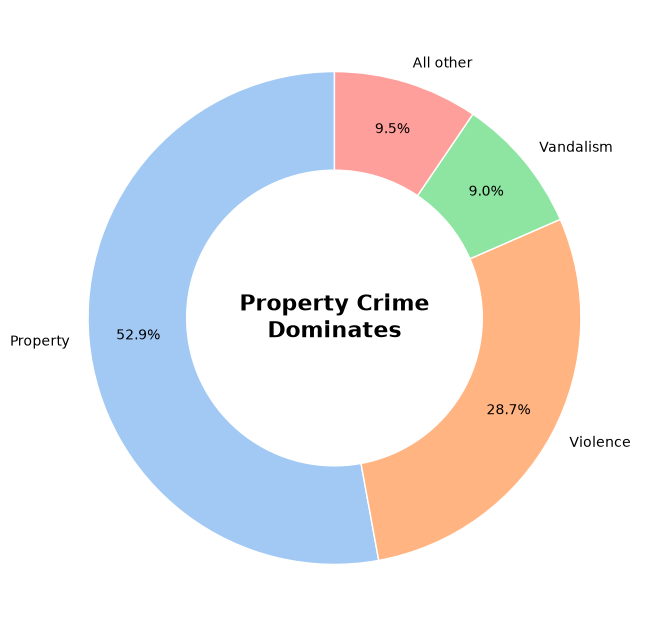

In [69]:
counts = crime["crime_category"].value_counts()
plot_data = counts.head(3).copy()
plot_data["All other"] = counts.iloc[3:].sum()
plt.figure(figsize=(8, 8))
plt.pie(plot_data.values, labels=plot_data.index, autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette("pastel"),
        pctdistance=0.8, labeldistance=1.08,
        wedgeprops={"width": 0.4, "edgecolor": "white"})
plt.text(0, 0, "Property Crime\nDominates", ha="center", va="center",
         fontsize=16, fontweight="bold")
plt.show()

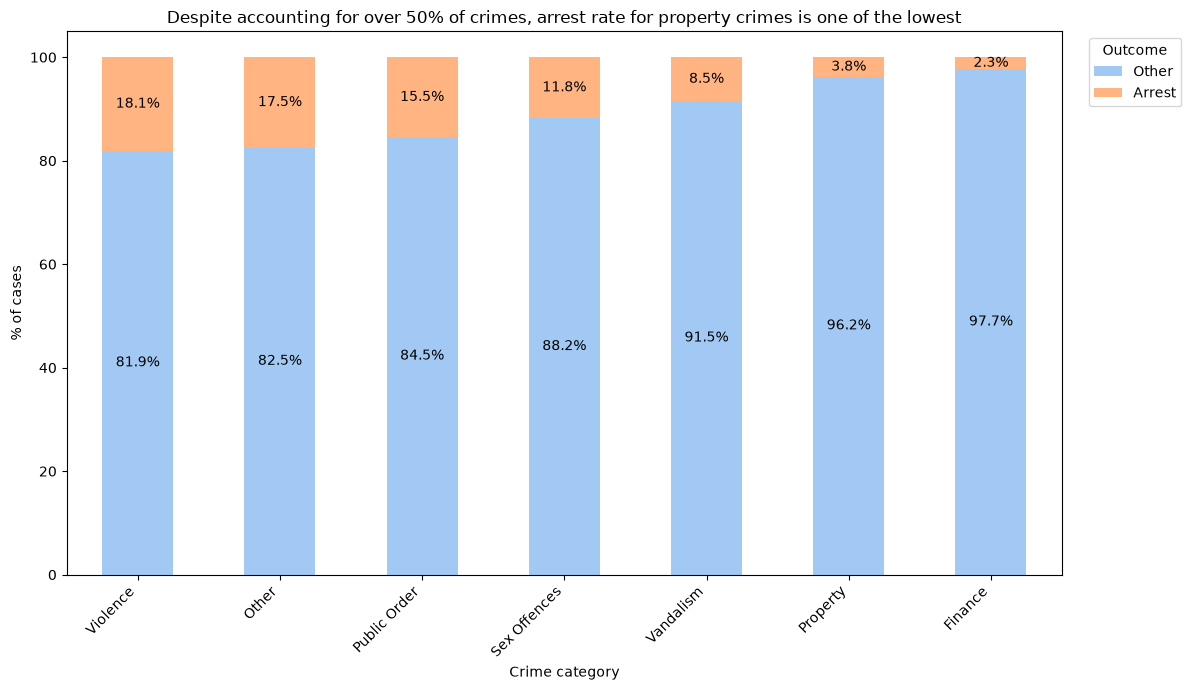

In [70]:
colours = sns.color_palette("pastel")[:2]
outcome_map = {
    "Adult Arrest": "Arrest",
    "Juv Arrest": "Arrest",
    "Adult Other": "Other",
    "Juv Other": "Other",
    "Invest Cont": "Other"
}
crime["outcome"] = crime["Status Desc"].map(outcome_map)

outcome_pct = (
    crime.groupby("crime_category")['outcome']
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .unstack()
)

outcome_pct = outcome_pct.sort_values("Arrest", ascending=False)
outcome_pct = outcome_pct[["Other", "Arrest"]]

ax = outcome_pct.plot(kind="bar", stacked=True, figsize=(12, 7), color=colours)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center")
    
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.title("Despite accounting for over 50% of crimes, arrest rate for property crimes is one of the lowest")
plt.xlabel("Crime category")
plt.ylabel("% of cases")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

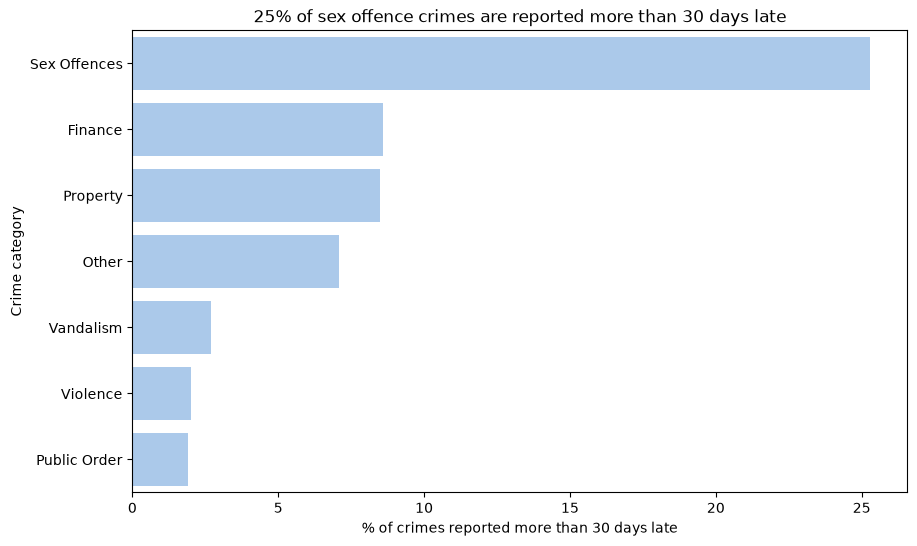

In [71]:
plt.figure(figsize=(10, 6))
sns.barplot(x=report_crime_pct.values, y=report_crime_pct.index, color=sns.color_palette("pastel")[0])
plt.title("25% of sex offence crimes are reported more than 30 days late")
plt.xlabel("% of crimes reported more than 30 days late")
plt.ylabel("Crime category")
plt.show()

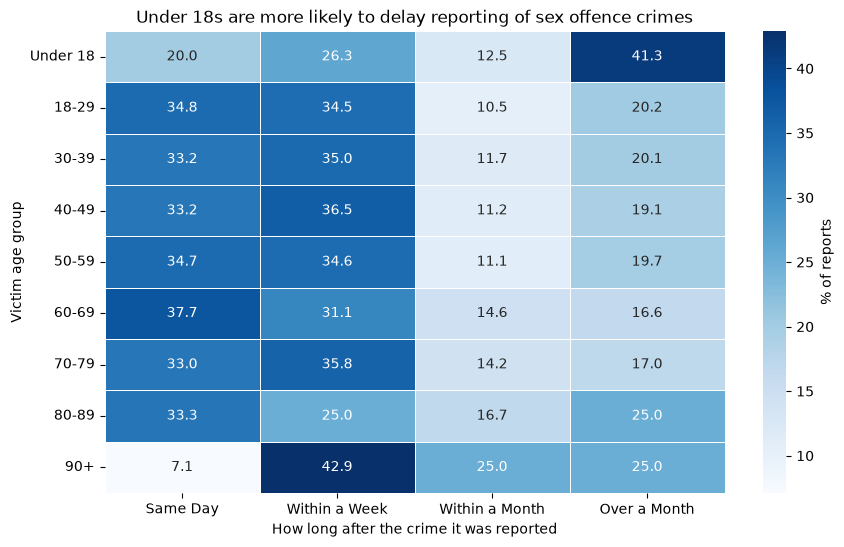

In [72]:
sex_offences = crime[crime["crime_category"] == "Sex Offences"]
age_order = ["Under 18", '18-29', "30-39", "40-49", "50-59",
             "60-69", "70-79", "80-89", "90+"]
delay_order = ["Same Day", "Within a Week", "Within a Month", "Over a Month"]
heat_data = (
    sex_offences.groupby("age_group")["delay_bracket"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .unstack()
)
heat_data = heat_data.reindex(age_order)
heat_data = heat_data[delay_order]
plt.figure(figsize=(10, 6))
sns.heatmap(heat_data, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "% of reports"})
plt.title("Under 18s are more likely to delay reporting of sex offence crimes")
plt.xlabel("How long after the crime it was reported")
plt.ylabel("Victim age group")
plt.show()

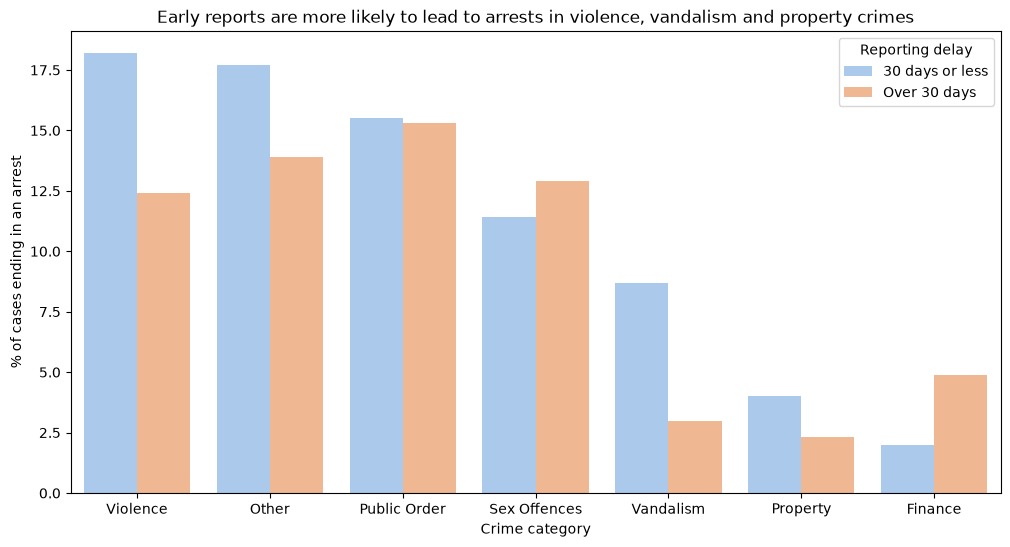

In [73]:
crime["report_timing"] = (crime["reporting_delay"] > 30).map({True: "Over 30 days", False: "30 days or less"})
arrest_by_timing = (
    (crime["outcome"] == "Arrest")
    .groupby([crime["crime_category"], crime["report_timing"]])
    .mean()
    .mul(100)
    .round(1)
    .reset_index(name="pct_arrested")
)
colours = sns.color_palette("pastel")[:2]
category_order = ["Violence", "Other", "Public Order", "Sex Offences",
                  "Vandalism", "Property", "Finance"]

plt.figure(figsize=(12, 6))
sns.barplot(data=arrest_by_timing, x="crime_category", y="pct_arrested",
            hue="report_timing", palette=colours, order=category_order)
plt.title("Early reports are more likely to lead to arrests in violence, vandalism and property crimes")
plt.xlabel("Crime category")
plt.ylabel("% of cases ending in an arrest")
plt.legend(title="Reporting delay")
plt.show()